# Cleaning + EDA + Feature Engineering — Yelp Business Demand

**Project:** Using Yelp Data to Estimate Business Demand and Identify Key Drivers
**Course:** DAMO-699-1 Capstone (Spring 2026)
**Team:** Sunghoon Ahn, Eun Soo Park, Thiri Htet Oo, Jayanthi Muthuselvan

This notebook merges the data-cleaning step (originally in `01_Capston_Data cleaning.ipynb`) with the exploratory data analysis and feature engineering pipeline (originally in `02_Result_EDA_FE_Yelp_Rev01.ipynb`) into a single end-to-end flow. Raw Yelp JSON files are loaded, cleaned (restaurant-only filter, null and duplicate removal, empty-text removal, trimming), and saved as cleaned Parquet. The cleaned data then feeds the EDA + feature engineering sections that produce the final business-level Parquet table for the modeling notebook.


## Dataset Source and Scope

The dataset used in this project is the Yelp Open Dataset, which provides business information, customer reviews, and check-in activity records.

Dataset source: https://business.yelp.com/data/resources/open-dataset/

This notebook uses three core datasets:

- `business.json`: business metadata, categories, location, attributes, and operating hours
- `review.json`: customer-generated review text, star ratings, review dates, and engagement counts
- `checkin.json`: customer check-in timestamps used as a proxy for business demand

The analytical scope is restricted to **restaurants** (businesses whose `categories` string contains "restaurant", case-insensitive). The unit of analysis is the business; review-level and check-in-level records are aggregated into business-level features using `business_id` as the common join key.

The final output is a business-level analytical dataset for downstream machine learning and SHAP-based driver analysis.


## Table of Contents

1. Setup
2. Load Raw JSON & Schema
3. Data Cleaning
4. Target Variable — Check-in Count + Log Transform
5. Review Features — EDA + Business-Level Aggregation
6. Sentiment Features (VADER, full review set)
7. Business Features — EDA + Flatten + Clean
8. Location Features — EDA + Coord Filter + Density
9. Temporal Features — EDA + Peak/Weekend Ratios
10. Data Quality Check
11. Integrate & Save
12. Summary


---
## 1. Setup

Install VADER (used in Section 6), restart Python, import libraries, and define the three Volume paths used by this pipeline:

- `RAW_PATH` — raw Yelp JSON files (output of `00_Download_Yelp_Dataset.ipynb`)
- `CLEANED_PATH` — cleaned Parquet written by Section 3 of this notebook
- `FEATURES_PATH` — final engineered features written by Section 11

Create the Volume once with `CREATE VOLUME IF NOT EXISTS workspace.default.yelp` in a SQL cell or through the Databricks UI before running this notebook.

This notebook is implemented using PySpark within Databricks to support scalable processing of large-scale Yelp JSON datasets containing millions of customer reviews and business activity records.


In [0]:
%pip install vaderSentiment --quiet


Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
dbutils.library.restartPython()


In [0]:
import pyspark.sql.functions as F
import pyspark.sql.types as T
from pyspark.sql.window import Window
from pyspark.sql.functions import pandas_udf, col, lower, trim

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# Paths
RAW_PATH       = "/Volumes/workspace/default/yelp"               # raw JSON
CLEANED_PATH   = "/Volumes/workspace/default/yelp/cleaned"       # cleaned Parquet (Section 3 output)
FEATURES_PATH  = "/Volumes/workspace/default/yelp/features"      # engineered features (Section 11 output)
OUTPUT_PATH    = f"{FEATURES_PATH}/business_features.parquet"
SENTIMENT_TMP  = f"{FEATURES_PATH}/_intermediate_sentiment.parquet"

# Plot defaults
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3


---
## 2. Load Raw JSON & Schema

Load the three core files (business, review, check-in) directly from the raw JSON Volume produced by `00_Download_Yelp_Dataset.ipynb`. User-level data is excluded per the project scope.

The row counts here are the first sanity check; they should match the documented April 2024 release sizes (business ≈ 150K, review ≈ 7M, check-in ≈ 132K). The schema check then confirms the column types and shows where the `business_id` join key sits in each table.

The Yelp datasets contain semi-structured JSON fields, including nested business attributes and complex categorical information. Therefore, schema inspection is necessary before preprocessing and feature engineering to validate column structures, data types, and nested field organization.


In [0]:
df_business = spark.read.json(f"{RAW_PATH}/yelp_academic_dataset_business.json")
df_review   = spark.read.json(f"{RAW_PATH}/yelp_academic_dataset_review.json")
df_checkin  = spark.read.json(f"{RAW_PATH}/yelp_academic_dataset_checkin.json")

print("=" * 50)
print("  Raw Dataset Row Counts")
print("=" * 50)
print(f"  Businesses: {df_business.count():>12,}")
print(f"  Reviews:    {df_review.count():>12,}")
print(f"  Check-ins:  {df_checkin.count():>12,}")
print("=" * 50)

print("\n=== Business Schema ===")
df_business.printSchema()

print("\n=== Review Schema ===")
df_review.printSchema()

print("\n=== Check-in Schema ===")
df_checkin.printSchema()


  Raw Dataset Row Counts
  Businesses:      150,346
  Reviews:       6,990,280
  Check-ins:       131,930

=== Business Schema ===
root
 |-- address: string (nullable = true)
 |-- attributes: struct (nullable = true)
 |    |-- AcceptsInsurance: string (nullable = true)
 |    |-- AgesAllowed: string (nullable = true)
 |    |-- Alcohol: string (nullable = true)
 |    |-- Ambience: string (nullable = true)
 |    |-- BYOB: string (nullable = true)
 |    |-- BYOBCorkage: string (nullable = true)
 |    |-- BestNights: string (nullable = true)
 |    |-- BikeParking: string (nullable = true)
 |    |-- BusinessAcceptsBitcoin: string (nullable = true)
 |    |-- BusinessAcceptsCreditCards: string (nullable = true)
 |    |-- BusinessParking: string (nullable = true)
 |    |-- ByAppointmentOnly: string (nullable = true)
 |    |-- Caters: string (nullable = true)
 |    |-- CoatCheck: string (nullable = true)
 |    |-- Corkage: string (nullable = true)
 |    |-- DietaryRestrictions: string (nullable 

---
## 3. Data Cleaning

**Why this step:** Raw Yelp JSON contains records outside the project scope (non-restaurant businesses), missing key fields, duplicates, and empty review text. The EDA and feature engineering sections downstream assume a clean, restaurant-only snapshot, so applying cleaning rules up front prevents dirty rows from leaking into aggregates and keeps the modeling unit (business) consistent across all derived tables.

**What this section does:** Apply cleaning rules to each of the three raw tables — business, review, and check-in — restrict the analytical scope to restaurants, save the cleaned tables as Parquet, and reload them so the rest of the notebook operates on a stable, on-disk snapshot. The business table is reduced to modeling-relevant columns, deduplicated by `business_id`, and filtered to restaurants only. The review table is similarly trimmed, deduplicated by `review_id`, freed of empty text, and inner-joined to the restaurant set. The check-in table is deduplicated and inner-joined the same way. A row-count check confirms the joins are consistent before the cleaned Parquet is written to `CLEANED_PATH`.

The cleaning principle is to (1) drop only what is clearly unusable — missing key columns, duplicates, empty review text — rather than imputing values that could distort downstream aggregates, and (2) align the three tables to the same restaurant-only business set via inner joins. Aligning the tables prevents a business from surviving in one source but disappearing from another, which would otherwise cause silent feature drops in the Section 11 join.

### Why Restaurant-Only Scope

The project hypotheses and methodology focus on customer demand patterns in restaurant businesses, where review activity, check-in behavior, and operational attributes (hours, delivery, takeout, price range) are most informative. Restaurants also dominate the Yelp Open Dataset by review volume and have the richest attribute and hours coverage, which makes them the most suitable subset for the EDA and feature engineering steps that follow.

### Cleaning Rules at a Glance

| Table | Drop nulls in | Deduplicate by | Other rules |
|---|---|---|---|
| business | `business_id`, `categories` | `business_id` | restaurant-only filter, trim `city`/`state` |
| review | `review_id`, `business_id`, `stars`, `text`, `date` | `review_id` | drop empty `text`, inner-join to business |
| check-in | `business_id`, `date` | `business_id` | inner-join to business |


### 3.1 Clean Business Data


In [0]:
df_business = df_business.select(
    "business_id", "name", "city", "state",
    "latitude", "longitude", "stars", "review_count",
    "categories", "attributes", "hours", "is_open",
)

df_business = df_business.dropna(subset=["business_id", "categories"])
df_business = df_business.dropDuplicates(["business_id"])

# Restaurant-only filter (project scope)
df_business = df_business.filter(
    lower(col("categories")).contains("restaurant")
)

# Trim whitespace from city/state to avoid spurious distinct values
df_business = (
    df_business
    .withColumn("city",  trim(col("city")))
    .withColumn("state", trim(col("state")))
)

print(f"Cleaned business rows: {df_business.count():,}")
df_business.show(3, truncate=80)


Cleaned business rows: 52,286
+----------------------+----------------------------+-------------+-----+----------+------------+-----+------------+--------------------------------------------------------------------------------+--------------------------------------------------------------------------------+-------------------------------------------------------------------------------+-------+
|           business_id|                        name|         city|state|  latitude|   longitude|stars|review_count|                                                                      categories|                                                                      attributes|                                                                          hours|is_open|
+----------------------+----------------------------+-------------+-----+----------+------------+-----+------------+--------------------------------------------------------------------------------+---------------------------------------

### 3.2 Clean Review Data


In [0]:
df_review = df_review.select(
    "review_id", "business_id", "user_id", "stars",
    "text", "date", "useful", "funny", "cool",
)

df_review = df_review.dropna(
    subset=["review_id", "business_id", "stars", "text", "date"]
)
df_review = df_review.dropDuplicates(["review_id"])
df_review = df_review.filter(trim(col("text")) != "")

# Inner-join to restaurant-only businesses
df_review = df_review.join(
    df_business.select("business_id"),
    on="business_id",
    how="inner",
)

print(f"Cleaned review rows: {df_review.count():,}")
df_review.show(3)


Cleaned review rows: 4,724,684
+--------------------+--------------------+--------------------+-----+--------------------+-------------------+------+-----+----+
|         business_id|           review_id|             user_id|stars|                text|               date|useful|funny|cool|
+--------------------+--------------------+--------------------+-----+--------------------+-------------------+------+-----+----+
|Zx7n8mdt8OzLRXVzo...|VN0oJh0TD2yKWUg0E...|ZihW6-M7xOl6v_fkk...|  5.0|lit!!!!! just wan...|2017-10-11 01:54:27|     0|    0|   0|
|BjBDHqHhMXSxgyVip...|_5Y0qP-S1O_kHULx0...|oAhoFRRKomodbIx8j...|  4.0|Came here for Sun...|2012-06-25 23:32:50|     2|    1|   1|
|t5RIuLUvE5fxr0TaR...|cRB01hp97-3IoSnw-...|Tv2F54uwjegG21PYT...|  5.0|We love this litt...|2017-03-04 00:03:17|     0|    0|   0|
+--------------------+--------------------+--------------------+-----+--------------------+-------------------+------+-----+----+
only showing top 3 rows


### 3.3 Clean Check-in Data


In [0]:
df_checkin = df_checkin.select("business_id", "date")
df_checkin = df_checkin.dropna(subset=["business_id", "date"])
df_checkin = df_checkin.dropDuplicates(["business_id"])

# Inner-join to restaurant-only businesses
df_checkin = df_checkin.join(
    df_business.select("business_id"),
    on="business_id",
    how="inner",
)

print(f"Cleaned check-in rows: {df_checkin.count():,}")
df_checkin.show(3)


Cleaned check-in rows: 51,318
+--------------------+--------------------+
|         business_id|                date|
+--------------------+--------------------+
|-nEsM53i_wmt9wpSl...|2015-05-18 18:06:...|
|-q0ziFleHQq3rPEhS...|2018-10-15 17:02:...|
|-ypIPYkJxDeAWSTEq...|2019-01-06 19:06:...|
+--------------------+--------------------+
only showing top 3 rows


### 3.4 Row Count Check


In [0]:
print("business_clean rows:", df_business.count())
print("review_clean rows:  ", df_review.count())
print("checkin_clean rows: ", df_checkin.count())

print()
print("unique business_id in business_clean:", df_business.select("business_id").distinct().count())
print("unique business_id in review_clean:  ", df_review.select("business_id").distinct().count())
print("unique business_id in checkin_clean: ", df_checkin.select("business_id").distinct().count())


business_clean rows: 52286
review_clean rows:   4724684
checkin_clean rows:  51318

unique business_id in business_clean: 52286
unique business_id in review_clean:   52286
unique business_id in checkin_clean:  51318


### 3.5 Save Cleaned Parquet + Reload


In [0]:
df_business.write.mode("overwrite").parquet(f"{CLEANED_PATH}/business_clean")
df_review.write.mode("overwrite").parquet(f"{CLEANED_PATH}/review_clean")
df_checkin.write.mode("overwrite").parquet(f"{CLEANED_PATH}/checkin_clean")

print(f"Cleaned Parquet saved to: {CLEANED_PATH}")

# Reload from disk so downstream sections read a stable snapshot
df_business = spark.read.parquet(f"{CLEANED_PATH}/business_clean")
df_review   = spark.read.parquet(f"{CLEANED_PATH}/review_clean")
df_checkin  = spark.read.parquet(f"{CLEANED_PATH}/checkin_clean")

print(f"\nReload check — business: {df_business.count():,}, review: {df_review.count():,}, checkin: {df_checkin.count():,}")


Cleaned Parquet saved to: /Volumes/workspace/default/yelp/cleaned

Reload check — business: 52,286, review: 4,724,684, checkin: 51,318


---
## 4. Target Variable — Check-in Count + Log Transform

**Why this step:** The target is the aggregated check-in count per business. The EDA confirmed it is extremely right-skewed (raw skew ≈ 50.75 in the full Yelp set; the restaurant-only subset is also long-tailed), so the methodology applies `log(1 + count)` before training. A small share of businesses has zero check-ins; they are kept as `0` rows because the absence itself is informative.

**What this section does:** Parse the comma-separated check-in timestamps into a count per business, left-join to the business table (zero check-ins → 0), add the log-transformed column, then plot the raw and log distributions side by side together with the skewness numbers.

**Why Check-in Activity Is Used as a Demand Proxy:** The Yelp dataset does not provide direct sales or transaction records. Therefore, customer check-in activity is used as a proxy variable for business demand. Check-in counts reflect customer visit activity and operational engagement, making them more behaviorally meaningful than review ratings alone. Although check-in activity does not perfectly represent actual revenue, it provides a practical and scalable indicator of customer demand within the Yelp ecosystem.


In [0]:
# Construct target — checkin_count + log version
df_checkin_count = (
    df_checkin
    .withColumn("checkin_count", F.size(F.split(F.col("date"), ", ")))
    .select("business_id", "checkin_count")
)

df_target = (
    df_business.select("business_id")
    .join(df_checkin_count, on="business_id", how="left")
    .withColumn("checkin_count", F.coalesce(F.col("checkin_count"), F.lit(0)))
    .withColumn("checkin_count_log", F.log1p(F.col("checkin_count")))
)

print(f"Target rows: {df_target.count():,}")
print(f"Businesses with 0 check-ins: {df_target.filter(F.col('checkin_count') == 0).count():,}")


Target rows: 52,286
Businesses with 0 check-ins: 968


                 0
min       0.000000
max   40109.000000
mean    162.865432
p50      44.000000
p90     394.000000
p99    1707.000000

Mean / Median: 3.70
Skew (raw):    25.59
Skew (log):    0.01


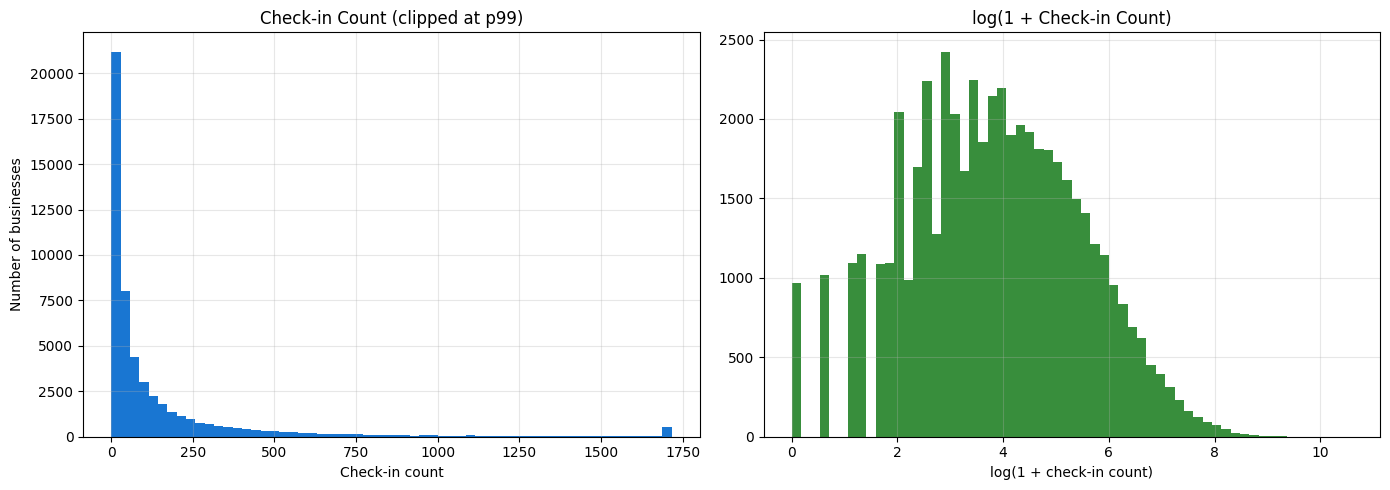

In [0]:
from scipy.stats import skew

# Summary stats on Spark side
stats = df_target.select(
    F.min("checkin_count").alias("min"),
    F.max("checkin_count").alias("max"),
    F.mean("checkin_count").alias("mean"),
    F.expr("percentile_approx(checkin_count, 0.50)").alias("p50"),
    F.expr("percentile_approx(checkin_count, 0.90)").alias("p90"),
    F.expr("percentile_approx(checkin_count, 0.99)").alias("p99"),
).toPandas()
print(stats.T)

# Collect and compute skewness
target_pd = df_target.select("checkin_count").toPandas()
raw_skew = skew(target_pd["checkin_count"])
log_skew = skew(np.log1p(target_pd["checkin_count"]))
print(f"\nMean / Median: {target_pd['checkin_count'].mean() / max(target_pd['checkin_count'].median(), 1):.2f}")
print(f"Skew (raw):    {raw_skew:.2f}")
print(f"Skew (log):    {log_skew:.2f}")

# Side-by-side histograms
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
p99 = target_pd["checkin_count"].quantile(0.99)
axes[0].hist(target_pd["checkin_count"].clip(upper=p99), bins=60, color="#1976d2")
axes[0].set_title("Check-in Count (clipped at p99)")
axes[0].set_xlabel("Check-in count")
axes[0].set_ylabel("Number of businesses")
axes[1].hist(np.log1p(target_pd["checkin_count"]), bins=60, color="#388e3c")
axes[1].set_title("log(1 + Check-in Count)")
axes[1].set_xlabel("log(1 + check-in count)")
plt.tight_layout()
plt.show()


---
## 5. Review Features — EDA + Business-Level Aggregation

**Why this step:** Reviews live at the review level (millions of rows), but the modeling unit is the business. The EDA first checks how reviews are spread across businesses and what star ratings look like, then the aggregation step produces one row per business with review-based features. `review_count` is also right-skewed, so a log version is added alongside the raw count.

**What this section does:** Plot the distribution of reviews per business and the star rating mix, then group by `business_id` to compute review count, average stars, average text length, sums of `useful` / `funny` / `cool`, and the log-transformed review count.

Because the modeling objective is business-level demand prediction, review-level observations are aggregated using `business_id`. This aggregation process converts multiple customer reviews into business-level statistical features suitable for downstream machine learning models.


### 5.1 EDA — Reviews per Business + Star Rating


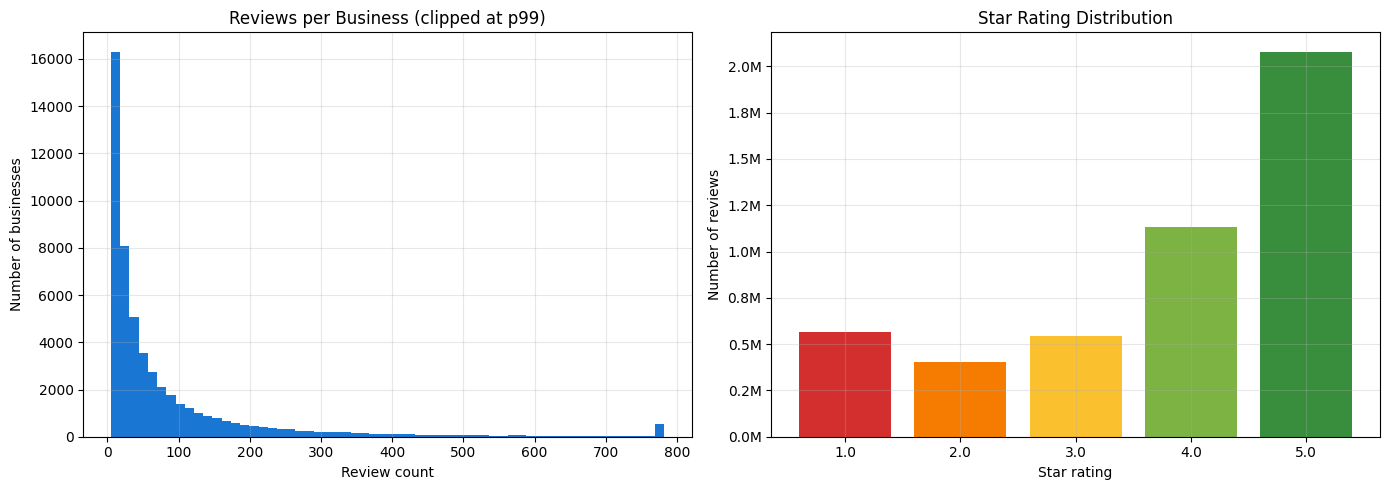

count    52286.0
mean        90.4
std        193.9
min          5.0
10%          7.0
50%         34.0
90%        214.0
99%        782.3
max       7673.0
Name: review_count, dtype: float64


In [0]:
# Reviews per business
reviews_per_biz = (
    df_review.groupBy("business_id").count()
    .withColumnRenamed("count", "review_count")
    .select("review_count").toPandas()
)

# Star rating distribution
rating_dist = df_review.groupBy("stars").count().orderBy("stars").toPandas()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
p99 = reviews_per_biz["review_count"].quantile(0.99)
axes[0].hist(reviews_per_biz["review_count"].clip(upper=p99), bins=60, color="#1976d2")
axes[0].set_title("Reviews per Business (clipped at p99)")
axes[0].set_xlabel("Review count")
axes[0].set_ylabel("Number of businesses")

colors = ["#d32f2f", "#f57c00", "#fbc02d", "#7cb342", "#388e3c"]
axes[1].bar(rating_dist["stars"].astype(str), rating_dist["count"], color=colors)
axes[1].set_title("Star Rating Distribution")
axes[1].set_xlabel("Star rating")
axes[1].set_ylabel("Number of reviews")
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M"))
plt.tight_layout()
plt.show()

print(reviews_per_biz["review_count"].describe([0.1, 0.5, 0.9, 0.99]).round(1))


### 5.2 Feature Engineering — Business-Level Review Aggregation


In [0]:
df_review_features = (
    df_review
    .groupBy("business_id")
    .agg(
        F.count("*").alias("review_count"),
        F.avg("stars").alias("avg_stars"),
        F.avg(F.length("text")).alias("avg_review_length"),
        F.sum("useful").alias("sum_useful"),
        F.sum("funny").alias("sum_funny"),
        F.sum("cool").alias("sum_cool"),
    )
    .withColumn("review_count_log", F.log1p(F.col("review_count")))
)

print(f"Review feature rows: {df_review_features.count():,}")
df_review_features.show(3)


Review feature rows: 52,286
+--------------------+------------+------------------+-----------------+----------+---------+--------+-----------------+
|         business_id|review_count|         avg_stars|avg_review_length|sum_useful|sum_funny|sum_cool| review_count_log|
+--------------------+------------+------------------+-----------------+----------+---------+--------+-----------------+
|I2Yt74AzSQFfyQqgN...|         146|2.6575342465753424|766.6232876712329|       127|       14|      24|4.990432586778736|
|VRnJgj0IvxoksHppE...|         238|3.7941176470588234|656.4705882352941|       355|      130|     180|5.476463551931511|
|iXemjTj5TOByT1-cN...|          65| 4.061538461538461|            430.2|        52|       14|      34|4.189654742026425|
+--------------------+------------+------------------+-----------------+----------+---------+--------+-----------------+
only showing top 3 rows


---
## 6. Sentiment Features (VADER, full review set)

**Why this step:** Star ratings alone do not separate businesses well (the EDA confirmed the 4–5 star concentration). Sentiment derived from review text adds a continuous tone signal. The methodology specifies VADER, which is lexicon-based, lightweight, and reproducible.

**Performance note:** VADER runs on the full review set so every business with at least one review contributes to its sentiment aggregate (no sampling-induced missingness). Databricks serverless has a 150-minute interactive timeout and does not allow `persist()`, so the aggregate is written to a Parquet checkpoint immediately to avoid recomputation on the Section 11 join. If a future run is cancelled by the timeout, the fallback is `.sample(fraction=0.5, seed=42)` together with the `sentiment_missing` flag and global-mean imputation that are already in place in Section 11.

**What this section does:** Define a pandas UDF for the VADER compound score, apply it to every review with non-null text, aggregate to business level (mean sentiment plus positive and negative ratios at the standard ±0.05 cutoffs), and save the aggregate to a Parquet checkpoint.

### **Why VADER?**

**VADER sentiment analysis is used because it is computationally efficient, interpretable, and well-suited for large-scale social-media-style textual data.**

Compared with transformer-based architectures such as BERT, VADER provides faster sentiment scoring and lower computational overhead, making it appropriate for exploratory large-scale feature generation in this study.


In [0]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

@pandas_udf(T.DoubleType())
def vader_compound(texts: pd.Series) -> pd.Series:
    analyzer = SentimentIntensityAnalyzer()
    return texts.fillna("").apply(lambda t: analyzer.polarity_scores(t)["compound"])

# Full review set — every business with non-null review text contributes
df_review_sentiment = (
    df_review
    .filter(F.col("text").isNotNull())
    .withColumn("sentiment", vader_compound(F.col("text")))
    .select("business_id", "sentiment")
)


In [0]:
df_sentiment_features = (
    df_review_sentiment
    .groupBy("business_id")
    .agg(
        F.avg("sentiment").alias("avg_sentiment"),
        F.avg((F.col("sentiment") >  0.05).cast("int")).alias("positive_ratio"),
        F.avg((F.col("sentiment") < -0.05).cast("int")).alias("negative_ratio"),
    )
)

# Save to Parquet checkpoint so downstream joins do not re-run VADER
df_sentiment_features.write.mode("overwrite").parquet(SENTIMENT_TMP)
df_sentiment_features = spark.read.parquet(SENTIMENT_TMP)

print(f"Sentiment feature rows: {df_sentiment_features.count():,}")
df_sentiment_features.show(3)


Sentiment feature rows: 52,286
+--------------------+-------------------+------------------+-------------------+
|         business_id|      avg_sentiment|    positive_ratio|     negative_ratio|
+--------------------+-------------------+------------------+-------------------+
|hWuLvI5QqPyQ1x9ww...| 0.4749421052631579|0.7368421052631579| 0.2631578947368421|
|SSxXyZFkA8U_DOeWz...|0.14223076923076924|0.6153846153846154|0.38461538461538464|
|DcBLYSvOuWcNReolR...| 0.6138135529996891|0.8483058750388561| 0.1405035747590923|
+--------------------+-------------------+------------------+-------------------+
only showing top 3 rows


---
## 7. Business Features — EDA + Flatten + Clean

**Why this step:** Business records carry the most varied structure of any table — a categories string, an `attributes` struct with around 40 fields, and an `hours` struct with seven daily entries. The EDA reports attribute and hours coverage on the cleaned set so the team can decide which attributes are usable directly. The methodology calls for flattening these structs into model-ready columns, using a missing-flag pattern instead of mode imputation so the model can learn from absence.

**What this section does:** Plot category and attribute coverage, then flatten the attributes struct into binary indicators with `*_missing` flags, parse the hours struct into weekly and weekend totals with `has_hours`, and replace any null categories with `"Unknown"` while adding derived flags such as `is_restaurant`.

### Business Feature Categories

| Feature Group | Example Variables | Purpose |
|---|---|---|
| Reputation Features | stars, review_count | Capture customer perception and popularity |
| Operational Features | hours, is_open | Capture operational availability |
| Attribute Features | delivery, takeout, parking | Capture service characteristics |
| Category Features | restaurant categories | Capture business type and market segment |


### 7.1 EDA — Top Categories


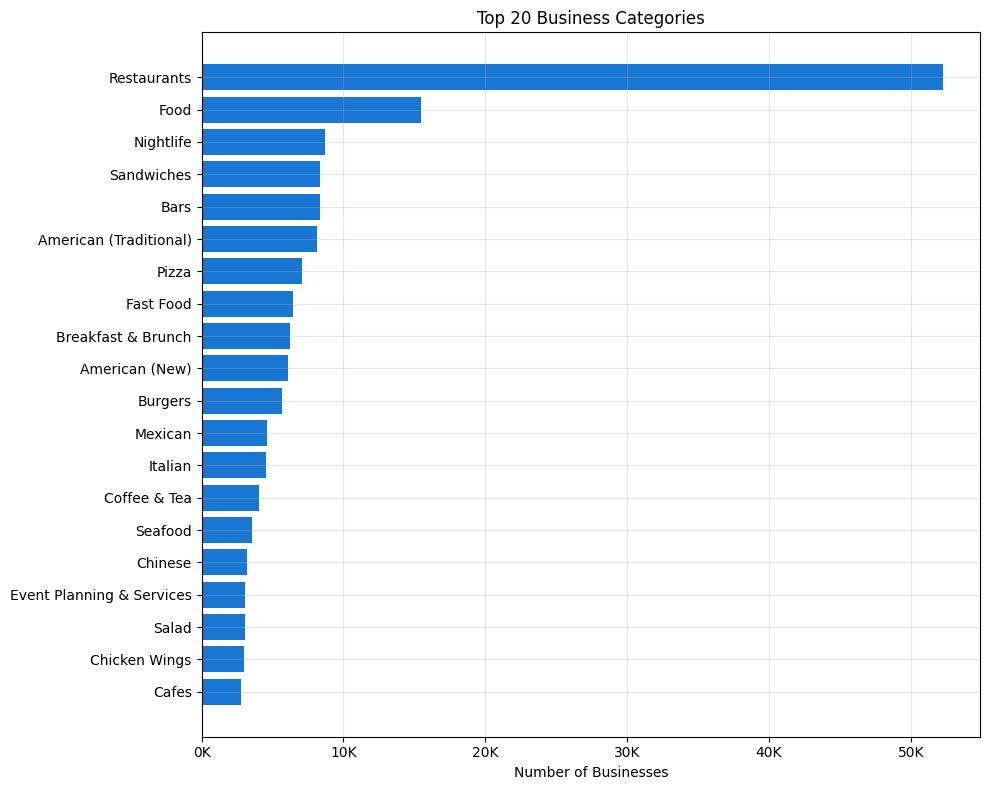

In [0]:
df_categories_top = (
    df_business
    .filter(F.col("categories").isNotNull())
    .withColumn("category", F.explode(F.split(F.col("categories"), ", ")))
    .groupBy("category").count()
    .orderBy(F.desc("count")).limit(20).toPandas()
)

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(df_categories_top["category"][::-1], df_categories_top["count"][::-1], color="#1976d2")
ax.set_xlabel("Number of Businesses")
ax.set_title("Top 20 Business Categories")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1e3:.0f}K"))
plt.tight_layout()
plt.show()


### 7.2 EDA — Attribute / Hours Coverage and is_open Ratio


In [0]:
total = df_business.count()

with_attrs = df_business.filter(F.col("attributes").isNotNull()).count()
print(f"Businesses with attributes: {with_attrs:,} / {total:,} ({with_attrs/total*100:.1f}%)")
print(f"Businesses with NO attributes: {total - with_attrs:,} ({(total - with_attrs)/total*100:.1f}%)")

with_hours = df_business.filter(F.col("hours").isNotNull()).count()
print(f"\nBusinesses with hours: {with_hours:,} / {total:,} ({with_hours/total*100:.1f}%)")
print(f"Businesses with NO hours: {total - with_hours:,} ({(total - with_hours)/total*100:.1f}%)")

open_dist = df_business.groupBy("is_open").count().orderBy("is_open").toPandas()
print("\n--- is_open ---")
print(open_dist)
open_ratio = open_dist[open_dist['is_open']==1]['count'].iloc[0] / open_dist['count'].sum()
print(f"Open businesses: {open_ratio*100:.1f}%")


Businesses with attributes: 51,720 / 52,286 (98.9%)
Businesses with NO attributes: 566 (1.1%)

Businesses with hours: 45,007 / 52,286 (86.1%)
Businesses with NO hours: 7,279 (13.9%)

--- is_open ---
   is_open  count
0        0  17282
1        1  35004
Open businesses: 66.9%


### 7.3 Feature Engineering — Flatten Attributes


In [0]:
df_attr = df_business.select(
    "business_id",
    F.when(F.col("attributes").isNull(), 0).otherwise(1).alias("has_attributes"),
    F.col("attributes.RestaurantsDelivery").alias("delivery_raw"),
    F.col("attributes.RestaurantsTakeOut").alias("takeout_raw"),
    F.col("attributes.OutdoorSeating").alias("outdoor_raw"),
    F.col("attributes.BusinessAcceptsCreditCards").alias("credit_raw"),
    F.col("attributes.RestaurantsPriceRange2").alias("price_raw"),
    F.col("attributes.GoodForKids").alias("good_for_kids_raw"),
)

def to_binary(col):
    return F.when(F.col(col) == "True", 1).when(F.col(col) == "False", 0).otherwise(None)

df_attr_clean = (
    df_attr
    .withColumn("delivery",      to_binary("delivery_raw"))
    .withColumn("takeout",       to_binary("takeout_raw"))
    .withColumn("outdoor",       to_binary("outdoor_raw"))
    .withColumn("credit_cards",  to_binary("credit_raw"))
    .withColumn("good_for_kids", to_binary("good_for_kids_raw"))
    # try_cast — Yelp stores missing price as the string 'None', so .cast('int') fails.
    .withColumn("price_range",   F.expr("try_cast(price_raw as int)"))
    .withColumn("price_missing",    F.col("price_range").isNull().cast("int"))
    .withColumn("delivery_missing", F.col("delivery").isNull().cast("int"))
    .withColumn("takeout_missing",  F.col("takeout").isNull().cast("int"))
    .drop("delivery_raw", "takeout_raw", "outdoor_raw", "credit_raw",
          "price_raw", "good_for_kids_raw")
    .fillna(-1, subset=["delivery", "takeout", "outdoor", "credit_cards",
                         "good_for_kids", "price_range"])
)

print(f"Attribute feature rows: {df_attr_clean.count():,}")
df_attr_clean.show(3)


Attribute feature rows: 52,286
+--------------------+--------------+--------+-------+-------+------------+-------------+-----------+-------------+----------------+---------------+
|         business_id|has_attributes|delivery|takeout|outdoor|credit_cards|good_for_kids|price_range|price_missing|delivery_missing|takeout_missing|
+--------------------+--------------+--------+-------+-------+------------+-------------+-----------+-------------+----------------+---------------+
|LGqiubTmpJ-A1L5n7...|             1|       0|      1|      0|           1|            1|          1|            0|               0|              0|
|IYlUaKC9nICjiWdk-...|             1|       0|      1|      1|           1|            1|          2|            0|               0|              0|
|fVPPZWf5QghlCLYRY...|             1|      -1|     -1|      1|           1|            0|          2|            0|               1|              1|
+--------------------+--------------+--------+-------+-------+------------+

### 7.4 Feature Engineering — Flatten Hours


In [0]:
def parse_hours(col):
    parts = F.split(F.col(col), "-")
    start = F.split(parts.getItem(0), ":")
    end   = F.split(parts.getItem(1), ":")
    start_h = start.getItem(0).cast("double") + start.getItem(1).cast("double") / 60.0
    end_h   = end.getItem(0).cast("double")   + end.getItem(1).cast("double")   / 60.0
    return (
        F.when(F.col(col).isNull(), 0.0)
        .otherwise(F.when(end_h >= start_h, end_h - start_h).otherwise(end_h + 24 - start_h))
    )

df_hours = df_business.select(
    "business_id",
    F.when(F.col("hours").isNull(), 0).otherwise(1).alias("has_hours"),
    parse_hours("hours.Monday").alias("hours_mon"),
    parse_hours("hours.Tuesday").alias("hours_tue"),
    parse_hours("hours.Wednesday").alias("hours_wed"),
    parse_hours("hours.Thursday").alias("hours_thu"),
    parse_hours("hours.Friday").alias("hours_fri"),
    parse_hours("hours.Saturday").alias("hours_sat"),
    parse_hours("hours.Sunday").alias("hours_sun"),
)

df_hours_features = (
    df_hours
    .withColumn("hours_total_week", sum(F.col(c) for c in [
        "hours_mon", "hours_tue", "hours_wed", "hours_thu",
        "hours_fri", "hours_sat", "hours_sun"]))
    .withColumn("hours_weekend", F.col("hours_sat") + F.col("hours_sun"))
    .select("business_id", "has_hours", "hours_total_week", "hours_weekend")
)

print(f"Hours feature rows: {df_hours_features.count():,}")
df_hours_features.show(3)


Hours feature rows: 52,286
+--------------------+---------+----------------+-------------+
|         business_id|has_hours|hours_total_week|hours_weekend|
+--------------------+---------+----------------+-------------+
|LGqiubTmpJ-A1L5n7...|        1|           105.0|         30.0|
|IYlUaKC9nICjiWdk-...|        1|            49.0|         14.0|
|fVPPZWf5QghlCLYRY...|        0|             0.0|          0.0|
+--------------------+---------+----------------+-------------+
only showing top 3 rows


### 7.5 Feature Engineering — Categories Cleaning


In [0]:
df_categories = (
    df_business.select("business_id", "categories")
    .withColumn("categories", F.when(F.col("categories").isNull(), "Unknown")
                                .otherwise(F.col("categories")))
    .withColumn("n_categories", F.size(F.split(F.col("categories"), ", ")))
    .withColumn("is_restaurant", F.col("categories").contains("Restaurants").cast("int"))
    .withColumn("is_food",       F.col("categories").contains("Food").cast("int"))
)

print(f"Category feature rows: {df_categories.count():,}")
df_categories.show(3, truncate=80)


Category feature rows: 52,286
+----------------------+---------------------------------------------+------------+-------------+-------+
|           business_id|                                   categories|n_categories|is_restaurant|is_food|
+----------------------+---------------------------------------------+------------+-------------+-------+
|LGqiubTmpJ-A1L5n7dmc6g|Restaurants, Sandwiches, Pizza, Chicken Wings|           4|            1|      0|
|IYlUaKC9nICjiWdk-ShPlg|              Restaurants, Breakfast & Brunch|           2|            1|      0|
|fVPPZWf5QghlCLYRYec1rg|                         Restaurants, Chinese|           2|            1|      0|
+----------------------+---------------------------------------------+------------+-------------+-------+
only showing top 3 rows


---
## 8. Location Features — EDA + Coord Filter + Density

**Why this step:** Location influences demand directly (urban vs suburban) and indirectly through competition (more nearby businesses can mean either more spillover or more competition). The EDA confirmed Yelp's coverage is concentrated in a small set of cities, so encoding decisions should be made with that in mind. The methodology also calls for filtering coordinates outside North America bounds before computing spatial features.

**What this section does:** Plot the top cities, apply the coordinate filter (lat 24–55, lon −130 to −65) with a `coord_missing` indicator, and compute a simple `nearby_business_density` as the count of businesses sharing the same rounded latitude/longitude grid cell.

### Spatial Feature Limitation

The location-density features used in this notebook are based on approximate geographic grouping methods.

Although these features provide scalable estimates of local business concentration, more precise geospatial methods such as Haversine-distance-based competitor analysis may improve spatial accuracy in future work.


### 8.1 EDA — Top Cities


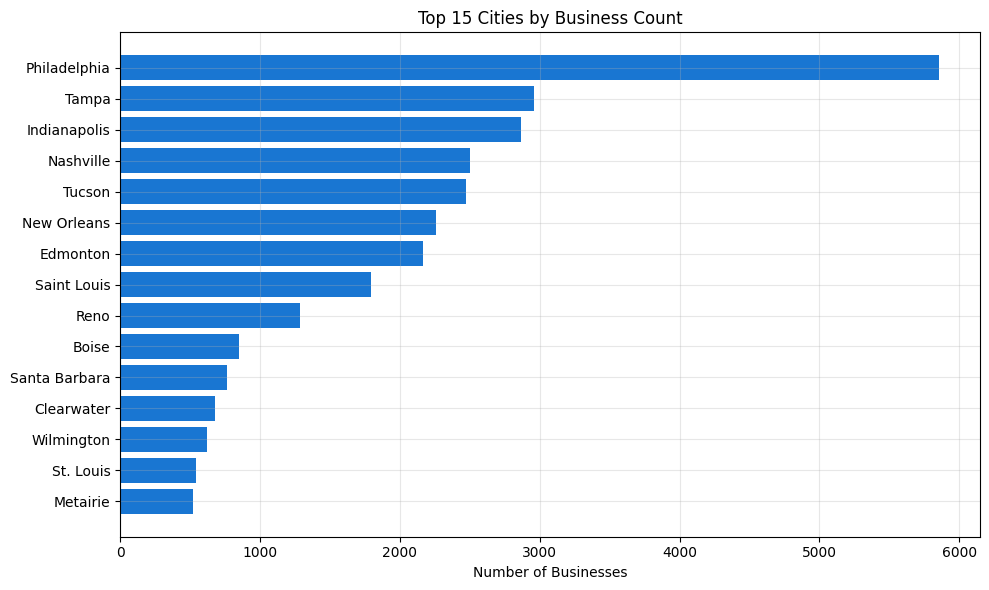

In [0]:
df_cities = (
    df_business.groupBy("city").count().orderBy(F.desc("count")).limit(15).toPandas()
)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(df_cities["city"][::-1], df_cities["count"][::-1], color="#1976d2")
ax.set_xlabel("Number of Businesses")
ax.set_title("Top 15 Cities by Business Count")
plt.tight_layout()
plt.show()


### 8.2 Feature Engineering — Coord Filter and Density


In [0]:
df_location_base = (
    df_business
    .select("business_id", "latitude", "longitude", "state", "city")
    .withColumn("latitude",
        F.when(F.col("latitude").between(24, 55), F.col("latitude")).otherwise(None))
    .withColumn("longitude",
        F.when(F.col("longitude").between(-130, -65), F.col("longitude")).otherwise(None))
    .withColumn("coord_missing",
        (F.col("latitude").isNull() | F.col("longitude").isNull()).cast("int"))
)

# Grid bucketing — round to 2 decimals ≈ 1.1 km cells
df_grid = (
    df_location_base
    .withColumn("lat_grid", F.round(F.col("latitude"), 2))
    .withColumn("lng_grid", F.round(F.col("longitude"), 2))
)

df_density = (
    df_grid.groupBy("lat_grid", "lng_grid").count()
    .withColumnRenamed("count", "nearby_business_density")
)

df_location_features = (
    df_grid.join(df_density, on=["lat_grid", "lng_grid"], how="left")
    .withColumn("nearby_business_density",
        F.coalesce(F.col("nearby_business_density"), F.lit(0)))
    .select("business_id", "latitude", "longitude", "state", "city",
            "coord_missing", "nearby_business_density")
)

loc_total = df_location_features.count()
loc_missing = df_location_features.filter(F.col("coord_missing") == 1).count()
print(f"Location feature rows: {loc_total:,}")
print(f"Filtered out by NA coord bounds: {loc_missing:,} ({loc_missing/loc_total*100:.2f}%)")
df_location_features.show(3)


Location feature rows: 52,286
Filtered out by NA coord bounds: 0 (0.00%)
+--------------------+----------+------------+-----+------+-------------+-----------------------+
|         business_id|  latitude|   longitude|state|  city|coord_missing|nearby_business_density|
+--------------------+----------+------------+-----+------+-------------+-----------------------+
|LGqiubTmpJ-A1L5n7...|29.8753202|  -90.045817|   LA|Harvey|            0|                     33|
|IYlUaKC9nICjiWdk-...| 39.976614|  -86.130124|   IN|Carmel|            0|                     43|
|fVPPZWf5QghlCLYRY...|32.3088305|-110.8454971|   AZ|Tucson|            0|                      9|
+--------------------+----------+------------+-----+------+-------------+-----------------------+
only showing top 3 rows


---
## 9. Temporal Features — EDA + Peak/Weekend Ratios

**Why this step:** Check-in activity is strongly time-dependent. The EDA shows clear hour-of-day and day-of-week shapes, so a business that gets most check-ins on weekend evenings behaves differently from one that is busiest on weekday mornings. The methodology turns those patterns into business-level ratios.

**What this section does:** Plot the hour-of-day and day-of-week histograms of all check-in events, then explode the timestamps and compute three per-business features: share of check-ins between 17:00 and 22:00 (`peak_hour_ratio`), share on Saturday or Sunday (`weekend_ratio`), and average check-ins per active month (`monthly_activity`).

Temporal features help capture differences in customer demand patterns across businesses. For example, businesses with high weekend activity may reflect leisure-oriented demand, while businesses with stronger weekday patterns may be associated with commuter or workday customer traffic.


### 9.1 EDA — Hour and Day-of-Week Patterns


Total check-in events: 8,515,582


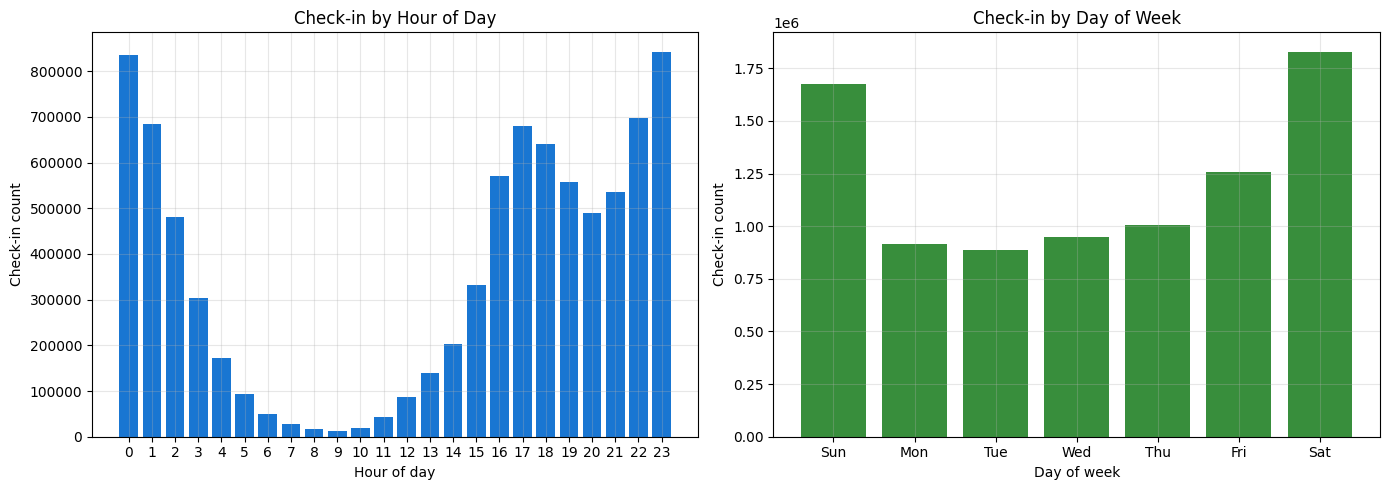

In [0]:
# Explode timestamps and aggregate by (hour, dow) in a single Spark pass
hour_dow_counts = (
    df_checkin
    .withColumn("checkin_ts", F.explode(F.split(F.col("date"), ", ")))
    .withColumn("checkin_ts", F.to_timestamp("checkin_ts"))
    .filter(F.col("checkin_ts").isNotNull())
    .withColumn("hour", F.hour("checkin_ts"))
    .withColumn("dow", F.dayofweek("checkin_ts"))   # 1 = Sun, 7 = Sat
    .groupBy("hour", "dow").count().toPandas()
)

by_hour = hour_dow_counts.groupby("hour")["count"].sum().reset_index().sort_values("hour")
by_dow  = hour_dow_counts.groupby("dow")["count"].sum().reset_index().sort_values("dow")
dow_labels = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]

print(f"Total check-in events: {hour_dow_counts['count'].sum():,}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(by_hour["hour"], by_hour["count"], color="#1976d2")
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("Check-in count")
axes[0].set_title("Check-in by Hour of Day")
axes[0].set_xticks(range(0, 24))
axes[1].bar(dow_labels, by_dow["count"], color="#388e3c")
axes[1].set_xlabel("Day of week")
axes[1].set_ylabel("Check-in count")
axes[1].set_title("Check-in by Day of Week")
plt.tight_layout()
plt.show()


### 9.2 Feature Engineering — Business-Level Temporal Features


In [0]:
df_checkin_events = (
    df_checkin
    .withColumn("checkin_ts", F.explode(F.split(F.col("date"), ", ")))
    .withColumn("checkin_ts", F.to_timestamp("checkin_ts"))
    .filter(F.col("checkin_ts").isNotNull())
    .withColumn("hour", F.hour("checkin_ts"))
    .withColumn("dow", F.dayofweek("checkin_ts"))
    .withColumn("ym", F.date_format("checkin_ts", "yyyy-MM"))
    .withColumn("is_peak",    F.col("hour").between(17, 22).cast("int"))
    .withColumn("is_weekend", F.col("dow").isin([1, 7]).cast("int"))
    .select("business_id", "is_peak", "is_weekend", "ym")
)

df_temporal_features = (
    df_checkin_events
    .groupBy("business_id")
    .agg(
        F.avg("is_peak").alias("peak_hour_ratio"),
        F.avg("is_weekend").alias("weekend_ratio"),
        (F.count("*") / F.countDistinct("ym")).alias("monthly_activity"),
    )
)

print(f"Temporal feature rows: {df_temporal_features.count():,}")
df_temporal_features.show(3)


Temporal feature rows: 51,318
+--------------------+-------------------+-------------------+------------------+
|         business_id|    peak_hour_ratio|      weekend_ratio|  monthly_activity|
+--------------------+-------------------+-------------------+------------------+
|3koeM2Blt-4rEmVIJ...|0.09424083769633508|0.39267015706806285|2.6901408450704225|
|2r3-fBAvSsljWrDLX...| 0.5915492957746479|0.30985915492957744| 7.675675675675675|
|3Yr-zJORfOhHakvRY...| 0.2350230414746544|0.45622119815668205| 4.018518518518518|
+--------------------+-------------------+-------------------+------------------+
only showing top 3 rows


---
## 10. Data Quality Check

**Why this step:** A final sanity check before the join — confirm there are no surprise nulls in key columns and no duplicate `business_id` or `review_id` rows that would inflate the dataset or break the join. The Section 3 cleaning should already have removed obvious issues, so this is a verification pass on the cleaned snapshot.

**What this section does:** Report null counts for the columns used in modeling and check key uniqueness across business, review, and check-in tables.


In [0]:
def null_report(df, name, cols):
    total = df.count()
    null_aggs = [F.sum(F.col(c).isNull().cast("int")).alias(c) for c in cols]
    null_counts = df.agg(*null_aggs).collect()[0].asDict()
    print(f"\n--- {name} (rows: {total:,}) ---")
    for c, n in null_counts.items():
        print(f"  {c}: {n:,} nulls ({n/total*100:.2f}%)")

null_report(df_business, "business",
    ["business_id", "city", "state", "latitude", "longitude",
     "stars", "review_count", "categories", "attributes", "hours", "is_open"])
null_report(df_review, "review",
    ["review_id", "user_id", "business_id", "stars", "text", "date"])
null_report(df_checkin, "checkin", ["business_id", "date"])

print()
print("--- Duplicate check ---")
print(f"business unique business_id: {df_business.select('business_id').distinct().count():,} / {df_business.count():,}")
print(f"review   unique review_id:   {df_review.select('review_id').distinct().count():,} / {df_review.count():,}")
print(f"checkin  unique business_id: {df_checkin.select('business_id').distinct().count():,} / {df_checkin.count():,}")



--- business (rows: 52,286) ---
  business_id: 0 nulls (0.00%)
  city: 0 nulls (0.00%)
  state: 0 nulls (0.00%)
  latitude: 0 nulls (0.00%)
  longitude: 0 nulls (0.00%)
  stars: 0 nulls (0.00%)
  review_count: 0 nulls (0.00%)
  categories: 0 nulls (0.00%)
  attributes: 566 nulls (1.08%)
  hours: 7,279 nulls (13.92%)
  is_open: 0 nulls (0.00%)

--- review (rows: 4,724,684) ---
  review_id: 0 nulls (0.00%)
  user_id: 0 nulls (0.00%)
  business_id: 0 nulls (0.00%)
  stars: 0 nulls (0.00%)
  text: 0 nulls (0.00%)
  date: 0 nulls (0.00%)

--- checkin (rows: 51,318) ---
  business_id: 0 nulls (0.00%)
  date: 0 nulls (0.00%)

--- Duplicate check ---
business unique business_id: 52,286 / 52,286
review   unique review_id:   4,724,684 / 4,724,684
checkin  unique business_id: 51,318 / 51,318


---
## 11. Integrate & Save

**Why this step:** Modeling needs one business-level table with the target and every engineered feature. Saving as Parquet lets the modeling notebook load it in seconds instead of recomputing every feature.

**What this section does:** Left-join all feature tables onto the full business list so businesses with no reviews or no check-ins still appear, add a `sentiment_missing` flag (a safety net — expected near zero under the full-VADER run, useful if a future run falls back to sampling), impute any missing sentiment rows with the global mean of covered businesses, fill remaining numeric nulls with 0 (absence is the right value for review_count, check-in ratios, and hours when those tables had no row for the business), validate row and column counts, and write the result to Parquet on the `features` Volume.

### Final Analytical Dataset

The final output of this notebook is a business-level analytical table.

Each row represents a single business, while columns represent engineered review, sentiment, business, spatial, and temporal features.

The resulting dataset will serve as the input for downstream machine learning models used for business demand prediction and SHAP-based driver analysis.


In [0]:
df_features = (
    df_business.select("business_id", "is_open", "stars")
    .withColumnRenamed("stars", "business_avg_stars")
    .join(df_target,             on="business_id", how="left")
    .join(df_review_features,    on="business_id", how="left")
    .join(df_sentiment_features, on="business_id", how="left")
    .join(df_attr_clean,         on="business_id", how="left")
    .join(df_hours_features,     on="business_id", how="left")
    .join(df_categories,         on="business_id", how="left")
    .join(df_location_features,  on="business_id", how="left")
    .join(df_temporal_features,  on="business_id", how="left")
)

# Safety net: flag any sentiment-missing rows (expected to be ~0 under the full-VADER run,
# non-zero only if a future run had to fall back to sampling). Computed BEFORE imputation so
# the model can still tell 'no data' (sentiment_missing=1) from 'measured neutral text'.
df_features = df_features.withColumn(
    "sentiment_missing", F.col("avg_sentiment").isNull().cast("int")
)

# Impute any missing sentiment rows with the global mean of covered businesses.
# With a full-set VADER run this typically has no effect; under a sampling fallback it
# keeps the linear baseline from being pulled toward zero by the missing share.
sent_means = df_sentiment_features.agg(
    F.avg("avg_sentiment").alias("m_sent"),
    F.avg("positive_ratio").alias("m_pos"),
    F.avg("negative_ratio").alias("m_neg"),
).collect()[0]
print(f"Sentiment global means — avg: {sent_means['m_sent']:.4f}, pos: {sent_means['m_pos']:.4f}, neg: {sent_means['m_neg']:.4f}")

df_features = df_features.fillna({
    "avg_sentiment":  sent_means["m_sent"],
    "positive_ratio": sent_means["m_pos"],
    "negative_ratio": sent_means["m_neg"],
})

# All other numeric features: 0 is the right fill (no reviews → 0 review_count; no check-ins → 0 ratios).
numeric_fill_zero = [
    "review_count", "sum_useful", "sum_funny", "sum_cool",
    "review_count_log",
    "peak_hour_ratio", "weekend_ratio", "monthly_activity",
    "hours_total_week", "hours_weekend",
]
df_features = df_features.fillna(0, subset=numeric_fill_zero)

print(f"Final rows: {df_features.count():,}")
print(f"Final cols: {len(df_features.columns)}")
df_features.show(3, truncate=50)


Sentiment global means — avg: 0.5772, pos: 0.8086, neg: 0.1745
Final rows: 52,286
Final cols: 42
+----------------------+-------+------------------+-------------+-----------------+------------+------------------+------------------+----------+---------+--------+------------------+--------------------+------------------+-------------------+--------------+--------+-------+-------+------------+-------------+-----------+-------------+----------------+---------------+---------+----------------+-------------+--------------------------------------------------+------------+-------------+-------+-------------+--------------+-----+-----------------+-------------+-----------------------+-------------------+-------------------+------------------+-----------------+
|           business_id|is_open|business_avg_stars|checkin_count|checkin_count_log|review_count|         avg_stars| avg_review_length|sum_useful|sum_funny|sum_cool|  review_count_log|       avg_sentiment|    positive_ratio|     negative_r

In [0]:
(df_features
 .write
 .mode("overwrite")
 .parquet(OUTPUT_PATH))

print(f"Saved feature table to: {OUTPUT_PATH}")

df_check = spark.read.parquet(OUTPUT_PATH)
print(f"Reload check — rows: {df_check.count():,}, cols: {len(df_check.columns)}")


Saved feature table to: /Volumes/workspace/default/yelp/features/business_features.parquet
Reload check — rows: 52,286, cols: 42


---
## 12. Summary

### What was produced

- Cleaned Parquet tables at `/Volumes/workspace/default/yelp/cleaned/` (business, review, check-in) — restaurant-only, deduplicated, with nulls and empty text removed.
- A business-level feature Parquet at `/Volumes/workspace/default/yelp/features/business_features.parquet` with one row per business plus the target and all engineered features.
- A sentiment checkpoint at `/Volumes/workspace/default/yelp/features/_intermediate_sentiment.parquet` (kept so re-runs do not need to re-execute VADER).

### Cleaning rules applied (Section 3)

- Restaurant-only filter on `business.categories` (case-insensitive substring "restaurant").
- `dropna` on key columns (`business_id`, `categories` for business; `review_id`, `business_id`, `stars`, `text`, `date` for review; `business_id`, `date` for check-in).
- `dropDuplicates` on `business_id` (business, check-in) and `review_id` (review).
- Empty review text removed (`trim(text) != ""`).
- `city` and `state` trimmed to avoid spurious distinct values.
- Inner-join review and check-in tables to the restaurant-only business set.

### EDA findings that drove feature engineering

- Target check-in count is right-skewed even on the restaurant subset — `log(1 + count)` transformation applied.
- A small share of restaurants has zero check-ins — kept as `0` because absence is informative.
- `attributes` and `hours` have non-trivial missing rates — handled with missing-flag pattern instead of mode imputation.
- Star ratings concentrate on 4–5 — raw stars alone do not separate businesses, so sentiment, length, and engagement features are added.
- A small number of metro areas dominate the dataset — category and city need careful encoding in the modeling step.
- Clear hour-of-day and day-of-week patterns in check-ins — turned into `peak_hour_ratio` and `weekend_ratio`.

### Cleaning and transformations applied (feature engineering)

- `log(1 + checkin_count)` on the target and `log(1 + review_count)` on the review-count feature.
- `attributes` struct flattened into binary indicators with `*_missing` flags.
- `hours` struct flattened into weekly and weekend totals plus a `has_hours` flag.
- Null `categories` replaced with `"Unknown"`; `is_restaurant` and `is_food` flags added.
- Coordinates outside North America bounds set to null and flagged with `coord_missing`; a 1-km grid density column added.
- VADER sentiment computed on every review with non-null text, aggregated to business level, checkpointed to Parquet. A `sentiment_missing` flag and global-mean imputation in Section 11 stay in place as a safety net if a future run has to fall back to sampling.
- Numeric nulls from businesses with no reviews or no check-ins filled with 0.

The engineered business-level dataset produced in this notebook will be used in subsequent modeling notebooks for regression analysis, ensemble machine learning, and SHAP-based interpretability analysis.

### Next step

Run the modeling notebook (`03_Modeling_Phase_Rev02.ipynb`), which loads `business_features.parquet`, performs a business-level train/validation/test split, encodes high-cardinality categoricals on training data only, and trains Linear Regression, XGBoost, and LightGBM on `checkin_count_log`. SHAP is then applied to the best model to identify the drivers of predicted demand.
